# Задача 4.6
# Встреча при ожидании 10 и 12 минут

## Условие
Лица A и B независимо приходят между 14 и 15 часами. A ждёт 10 минут, B — 12 минут. Найти вероятность встречи и оценить её по $N=150000$ опытам.

## Теория с нуля и решение вручную
### 1. Геометрическая вероятность
Пусть $x$ и $y$ — минуты прихода A и B после 14:00. Предполагаем независимые равномерные распределения на $[0,60]$. Пара $(x,y)$ равномерна в квадрате площади $60^2=3600$. Поэтому вероятность области равна её площади, делённой на 3600. Равномерность и независимость — существенные предположения модели.

### 2. Неравенства встречи
Если A пришёл раньше, нужен приход B не позднее ухода A: $y\le x+10$. Если B пришёл раньше, нужен $x\le y+12$. Объединённая запись:
$$A_{\text{встреча}}=\{-12\le y-x\le10\}.$$
Такое условие одновременно охватывает оба порядка прихода. Точки на границе не влияют на вероятность, поскольку имеют нулевую площадь.

### 3. Вычитаем два треугольника
Невстреча: либо $y>x+10$, либо $x>y+12$. Области несовместны, это прямоугольные равнобедренные треугольники с катетами 50 и 48 минут:
$$P(\text{встреча})=1-\frac{50^2/2+48^2/2}{3600}=\frac{599}{1800}\approx0.33277778.$$
Общая формула при длине интервала $L$ и ожиданиях $u,v\in[0,L]$:
$$P=1-\frac{(L-u)^2+(L-v)^2}{2L^2}.$$
Проверка: нулевые ожидания дают вероятность 0, ожидания по целому часу — 1.

### 4. Переход к коду
Создаём две независимые координаты в квадрате и проверяем ровно два неравенства из пункта 2. Один опыт — одна пара приходов. Частота будет близка к точному ответу, но не обязана совпасть с примером из PDF.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Встреча при ожиданиях 10 и 12 минут: успехов 49997, знаменатель 150000
  частота = 0.33331333; ориентир 95%: [0.33092773; 0.33569893]
  теория = 0.33277778; разность = +0.00053556


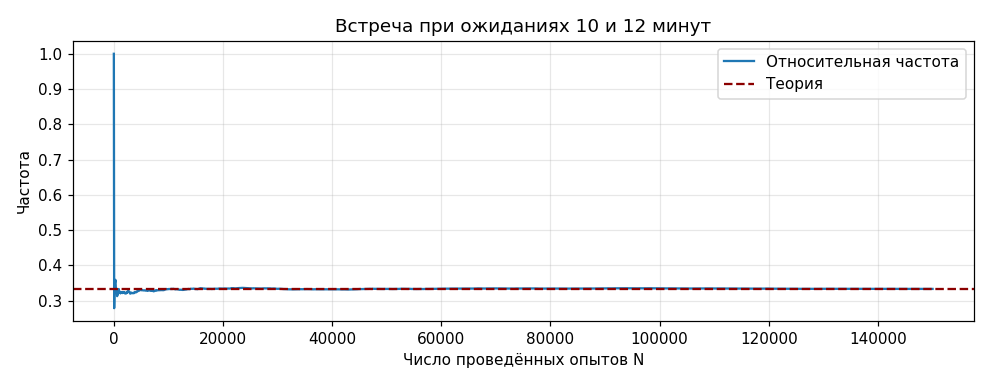

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
x = rng.uniform(0, 60, N)
y = rng.uniform(0, 60, N)
meeting = (y-x <= 10) & (x-y <= 12)
report(meeting, 'Встреча при ожиданиях 10 и 12 минут', Fraction(599, 1800))
